# New dataset - RSNA Pneumonia Detection Challenge

In [1]:
import os
import zipfile
import subprocess
from google.colab import userdata

print("--- 1. Authentication ---")
try:
    # Fetch the new API token from Colab Secrets
    api_token = userdata.get('KAGGLE_API_TOKEN').strip()

    # Set it as an environment variable (this is exactly what the new Kaggle CLI asked for)
    os.environ['KAGGLE_API_TOKEN'] = api_token
    print("✅ New Kaggle API Token configured securely!")

except userdata.SecretNotFoundError:
    print("❌ ERROR: Could not find KAGGLE_API_TOKEN in Secrets.")
    print("Please add it in the Secrets tab on the left.")

print("\n--- 2. Dataset Acquisition ---")
dataset_name = "rsna-pneumonia-detection-challenge"
data_dir = "rsna-pneumonia-detection-challenge"
zip_path = f"{dataset_name}.zip"

# Only attempt download if we successfully loaded the token
if 'KAGGLE_API_TOKEN' in os.environ:
    if not os.path.exists(data_dir):
        print("Downloading dataset via Kaggle API...")

        command = ["kaggle", "competitions", "download", "-c", dataset_name]
        result = subprocess.run(command, capture_output=True, text=True)

        if result.returncode != 0:
            print("❌ ERROR: Download failed!")
            print("--- KAGGLE'S ERROR MESSAGE ---")
            print(result.stderr if result.stderr else result.stdout)
            print("------------------------------")
        elif not os.path.exists(zip_path):
            print(f"❌ ERROR: Command succeeded, but {zip_path} was not found.")
        else:
            print("Extracting files...")
            with zipfile.ZipFile(zip_path, 'r') as zip_ref:
                zip_ref.extractall(data_dir)
            os.remove(zip_path)
            print("✅ Dataset downloaded and extracted successfully.")
    else:
        print("✅ Dataset already exists in the local Colab environment.")

--- 1. Authentication ---
✅ New Kaggle API Token configured securely!

--- 2. Dataset Acquisition ---
Extracting files...
✅ Dataset downloaded and extracted successfully.


### Cell 1: Imports and Setup

This cell handles all necessary imports, including PyTorch, Torchvision, Captum, and other utilities. It also configures the device (CUDA, MPS, or CPU) to ensure the code runs on available hardware.

In [2]:
pip install captum pydicom

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 81.0 MB/s eta 0:00:00


In [3]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

import pydicom
from google.colab import drive

# Captum imports for Explainable AI (XAI)
from captum.attr import LayerAttribution, LayerGradCam
from captum.attr import visualization as viz

# --- Setup ---
print(f"PyTorch Version: {torch.__version__}")

# Device configuration
if torch.cuda.is_available():
    device = torch.device("cuda")
    print("Using GPU: CUDA")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("Using GPU: MPS")
else:
    device = torch.device("cpu")
    print("Using CPU")

# For reproducibility
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

PyTorch Version: 2.11.0+cu128
Using GPU: CUDA


In [4]:
!kaggle --version

Kaggle CLI 2.0.2


### Save the model

In [5]:
# This will prompt you to log in and grant Colab access to your Drive
drive.mount('/content/drive')

# Define exactly where in your Drive you want to save the model

# Find the correct directory in the sidebar, inside /content/drive/MyDrive/...
# Paste the path you copied from the left sidebar here:
notebook_dir = '/content/drive/MyDrive/Progetto_Pneumonia_Shared'

# This joins the directory path with the file name automatically
# "v1" - solo layer fc unfreezed
model_save_path = os.path.join(notebook_dir, 'pneumonia_resnet50_weights.pth')
# New version to be saved ->
# "v2" training con layer3 e layer4 unfreezed (and last fc layer)
model_save_path = os.path.join(notebook_dir, 'pneumonia_resnet50_weights_v2.pth')
# "v2.1" training con layer3 e layer4 unfreezed (and last fc layer)
model_save_path = os.path.join(notebook_dir, 'pneumonia_resnet50_weights_v2.1.pth')
# "v3" training with all layers unfreezed
  # 5 epochs are not enough. Should be 50 like in the original paper.
# model_save_path = os.path.join(notebook_dir, 'pneumonia_resnet50_weights_v3.pth')
# "v4" training con layer3 e layer4 unfreezed, 50 epochs (from here)
# model_save_path = os.path.join(notebook_dir, 'pneumonia_resnet50_weights_v4.pth')

print(f"Model will be saved to and loaded from: {model_save_path}")

Mounted at /content/drive
Model will be saved to and loaded from: /content/drive/MyDrive/Progetto_Pneumonia_Shared/pneumonia_resnet50_weights_v2.1.pth


### Cell 2: Custom PyTorch Dataset

This `PneumoniaDataset` class loads images and their corresponding metadata (labels, bounding boxes) from a CSV file. It applies necessary transformations to prepare the data for the ResNet50 model. For demonstration, it includes code to create dummy data, making the notebook runnable out-of-the-box.

In [6]:
# --- Define Separated Transformations ---

# Training transforms include the augmentations mentioned in the paper
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Validation and Test transforms should NEVER include random augmentations
val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class PneumoniaDataset(Dataset):
    """
    Custom PyTorch Dataset for the RSNA Pneumonia Detection Challenge.
    """
    def __init__(self, dataframe, img_folder, transform=None):
        """
        Args:
            dataframe (pd.DataFrame): Pre-filtered dataframe with annotations.
            img_folder (string): Directory with all the images.
            transform (callable, optional): Transform to be applied on a sample.
        """
        self.df = dataframe.reset_index(drop=True)
        self.img_folder = img_folder
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()

        row = self.df.iloc[idx]

        img_name = os.path.join(self.img_folder, f"{row['patientId']}.dcm")
        dcm = pydicom.dcmread(img_name)
        image = Image.fromarray(dcm.pixel_array).convert("RGB")

        label = int(row['Target'])
        bbox = [row['x'], row['y'], row['width'], row['height']]

        if np.isnan(bbox).any():
            bbox = [0, 0, 0, 0]

        bbox = torch.tensor(bbox, dtype=torch.float32)

        if self.transform:
            image = self.transform(image)

        return image, label, bbox

In [7]:
class MRSDataset(Dataset):
    """
    Dedicated dataset for MRS evaluation.
    Aggregates all bounding boxes per patient into a single, unified binary mask.
    """
    def __init__(self, dataframe, img_folder, transform=None):
        self.img_folder = img_folder
        self.transform = transform

        # Group by patientId and Target to gather all bounding boxes into a list
        self.grouped_df = dataframe.groupby(['patientId', 'Target']).apply(
            lambda df: [
                [row['x'], row['y'], row['width'], row['height']]
                for _, row in df.iterrows() if not np.isnan(row['width'])
            ],
            include_groups=False
        ).reset_index(name='bboxes')

    def __len__(self):
        return len(self.grouped_df)

    def __getitem__(self, idx):
        row = self.grouped_df.iloc[idx]
        img_name = os.path.join(self.img_folder, f"{row['patientId']}.dcm")
        dcm = pydicom.dcmread(img_name)
        image = Image.fromarray(dcm.pixel_array).convert("RGB")

        label = int(row['Target'])

        if self.transform:
            image = self.transform(image)

        # Generate a unified 224x224 mask covering ALL bounding boxes
        new_h, new_w = 224, 224
        mask = np.zeros((new_h, new_w), dtype=np.float32)

        if label == 1:
            orig_h, orig_w = 1024, 1024
            x_scale, y_scale = new_w / orig_w, new_h / orig_h

            for bbox in row['bboxes']:
                x, y, w, h = bbox
                if w > 0 and h > 0:
                    x_scaled = int(x * x_scale)
                    y_scaled = int(y * y_scale)
                    w_scaled = int(w * x_scale)
                    h_scaled = int(h * y_scale)

                    y_end = min(y_scaled + h_scaled, new_h)
                    x_end = min(x_scaled + w_scaled, new_w)

                    # Add this box to the unified mask
                    mask[y_scaled:y_end, x_scaled:x_end] = 1.0

        return image, label, torch.tensor(mask)

### Cell 2.1: Splitting the Dataset into Training and Validation Sets

To properly evaluate our model's generalization capabilities and monitor for overfitting, we split the `pneumonia_dataset` into a training set and a validation set. A common split ratio is 80% for training and 20% for validation.

We then create separate `DataLoader` instances for each set, allowing for batch processing during training and evaluation.

In [8]:
csv_path = 'rsna-pneumonia-detection-challenge/stage_2_train_labels.csv'
img_folder = 'rsna-pneumonia-detection-challenge/stage_2_train_images'

# 1. Load the full dataframe
full_df = pd.read_csv(csv_path)

# 2. Extract unique patient IDs and shuffle them
unique_patients = full_df['patientId'].unique()
np.random.seed(42) # For reproducibility
np.random.shuffle(unique_patients)

# 3. Calculate split indices (70% Train, 15% Val, 15% Test)
train_split = int(0.70 * len(unique_patients))
val_split = int(0.85 * len(unique_patients))

train_ids = unique_patients[:train_split]
val_ids = unique_patients[train_split:val_split]
test_ids = unique_patients[val_split:]

# 4. Filter the main dataframe using the separated IDs
train_df = full_df[full_df['patientId'].isin(train_ids)]
val_df = full_df[full_df['patientId'].isin(val_ids)]
test_df = full_df[full_df['patientId'].isin(test_ids)]

print(f"Total Unique Patients: {len(unique_patients)}")
print(f"Train samples (includes multi-boxes): {len(train_df)}")
print(f"Validation samples: {len(val_df)}")
print(f"Test samples: {len(test_df)}")

# 5. Instantiate the datasets with the correct transforms
train_dataset = PneumoniaDataset(train_df, img_folder, transform=train_transform)
val_dataset = PneumoniaDataset(val_df, img_folder, transform=val_test_transform)
test_dataset = PneumoniaDataset(test_df, img_folder, transform=val_test_transform)

# 6. Create DataLoaders
train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_dataloader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

Total Unique Patients: 26684
Train samples (includes multi-boxes): 21148
Validation samples: 4535
Test samples: 4544


### Cell 4.1: Validation Loop Function

We introduce a `validate_one_epoch` function, similar to the training function, but without backpropagation and optimizer steps. This function will evaluate the model's performance on the validation set after each training epoch, providing insights into its generalization ability. The model is set to evaluation mode (`model.eval()`) to disable dropout and batch normalization updates.

In [9]:
def validate_one_epoch(model, dataloader, criterion, device):
    model.eval()  # Set model to evaluation mode

    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    with torch.no_grad():  # Disable gradient calculation for validation
        for images, labels, _ in dataloader:
            images = images.to(device)
            labels = labels.to(device).float().unsqueeze(1)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            preds = torch.sigmoid(outputs) > 0.5
            correct_predictions += (preds == labels).sum().item()
            total_samples += labels.size(0)

    epoch_loss = running_loss / total_samples
    epoch_acc = correct_predictions / total_samples

    print(f"Validation Loss: {epoch_loss:.4f}, Accuracy: {epoch_acc:.4f}")
    return epoch_loss, epoch_acc

### Cell 3: Model Initialization

Here, we load a pre-trained ResNet50 model from `torchvision`. We freeze the weights of the convolutional base and replace the final fully connected layer (`fc`) with a new one tailored for our binary classification task (Pneumonia vs. Normal).

In [10]:
# Load a pre-trained ResNet50 model with the latest recommended weights
model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)

# --- Freeze all layers in the network ---
# This is a common practice in transfer learning to prevent overfitting on small datasets.
for param in model.parameters():
    param.requires_grad = False

# UNFREEZE the later layers so they can learn X-ray features
for param in model.layer3.parameters():
    param.requires_grad = True
for param in model.layer4.parameters():
    param.requires_grad = True

# Get the number of input features for the classifier
num_ftrs = model.fc.in_features

# --- Replace the final fully connected layer ---
# We replace it with a new nn.Linear layer for binary classification (1 output neuron).
# The output will be raw logits, suitable for BCEWithLogitsLoss.
model.fc = nn.Linear(num_ftrs, 1)

# Note: The new layer's parameters have `requires_grad=True` by default.
# Only the weights of this new classifier head will be trained.

# Move the model to the configured device
model = model.to(device)

# You can check which parameters are trainable
print("Trainable parameters:")
for name, param in model.named_parameters():
    if param.requires_grad:
        print(name)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 180MB/s]


Trainable parameters:
layer3.0.conv1.weight
layer3.0.bn1.weight
layer3.0.bn1.bias
layer3.0.conv2.weight
layer3.0.bn2.weight
layer3.0.bn2.bias
layer3.0.conv3.weight
layer3.0.bn3.weight
layer3.0.bn3.bias
layer3.0.downsample.0.weight
layer3.0.downsample.1.weight
layer3.0.downsample.1.bias
layer3.1.conv1.weight
layer3.1.bn1.weight
layer3.1.bn1.bias
layer3.1.conv2.weight
layer3.1.bn2.weight
layer3.1.bn2.bias
layer3.1.conv3.weight
layer3.1.bn3.weight
layer3.1.bn3.bias
layer3.2.conv1.weight
layer3.2.bn1.weight
layer3.2.bn1.bias
layer3.2.conv2.weight
layer3.2.bn2.weight
layer3.2.bn2.bias
layer3.2.conv3.weight
layer3.2.bn3.weight
layer3.2.bn3.bias
layer3.3.conv1.weight
layer3.3.bn1.weight
layer3.3.bn1.bias
layer3.3.conv2.weight
layer3.3.bn2.weight
layer3.3.bn2.bias
layer3.3.conv3.weight
layer3.3.bn3.weight
layer3.3.bn3.bias
layer3.4.conv1.weight
layer3.4.bn1.weight
layer3.4.bn1.bias
layer3.4.conv2.weight
layer3.4.bn2.weight
layer3.4.bn2.bias
layer3.4.conv3.weight
layer3.4.bn3.weight
layer3.4.bn

### Cell 4: Training and Validation Loop

This cell defines the loss function (`BCEWithLogitsLoss`) and optimizer (`Adam`). It includes a concise function to perform one epoch of training, calculating loss and accuracy. This serves as a template for a full training script.

In [11]:
# --- Define Loss Function and Optimizer ---
# BCEWithLogitsLoss is ideal for binary classification with a single logit output.
criterion = nn.BCEWithLogitsLoss()
# criterion = nn.CrossEntropyLoss()

# The optimizer will only update the parameters of the final layer,
# as all other layers have been frozen.
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.001)

# --- Concise Training Loop (for one epoch) ---
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()  # Set model to training mode

    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for images, labels, _ in dataloader:
        images = images.to(device)
        # Ensure labels are float and have shape [batch_size, 1] for the loss function
        labels = labels.to(device).float().unsqueeze(1)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # --- Statistics ---
        running_loss += loss.item() * images.size(0)

        # Calculate accuracy by applying a sigmoid and thresholding at 0.5
        preds = torch.sigmoid(outputs) > 0.5
        correct_predictions += (preds == labels).sum().item()
        total_samples += labels.size(0)

    epoch_loss = running_loss / total_samples
    epoch_acc = correct_predictions / total_samples

    print(f"Training Loss: {epoch_loss:.4f}, Accuracy: {epoch_acc:.4f}")
    return epoch_loss, epoch_acc

### Actual training

### Cell 4.2: Actual Training with Validation and Early Stopping

This cell now contains the full training loop, incorporating the validation set. After each training epoch, the model is evaluated on the validation set. We will track the best validation accuracy and save the model weights only when a new best validation accuracy is achieved. This ensures that the saved model performs best on unseen data.

In [12]:
# --- Actual Training Loop with Validation and Model Saving ---

# --- Check for saved model or Train ---

if os.path.exists(model_save_path):
    # If the file exists, skip training and load the saved weights
    print(f"Found saved model at '{model_save_path}'. Loading weights...")

    # Load the state dictionary into the model architecture
    # map_location ensures it loads correctly whether you are currently using a GPU or CPU
    model.load_state_dict(torch.load(model_save_path, map_location=device, weights_only=True))
    print("✅ Model loaded successfully! You can skip to visualization.")

else:
    # If no file exists, train the model
    num_epochs = 5 # Set the desired number of epochs
    # num_epochs = 50 # Set the desired number of epochs # NOW 50 epochs!!
    best_val_accuracy = 0.0 # Initialize best validation accuracy

    # Initialize lists to store metrics for plotting
    train_losses = []
    train_accuracies = []
    val_losses = []
    val_accuracies = []

    print(f"No saved model found. Starting training for {num_epochs} epochs...")
    for epoch in range(num_epochs):
        print(f"--- Epoch {epoch+1}/{num_epochs} ---")
        # Train for one epoch and get metrics
        epoch_train_loss, epoch_train_acc = train_one_epoch(model, train_dataloader, criterion, optimizer, device)
        train_losses.append(epoch_train_loss)
        train_accuracies.append(epoch_train_acc)

        # Evaluate on the validation set and get metrics
        val_loss, val_acc = validate_one_epoch(model, val_dataloader, criterion, device)
        val_losses.append(val_loss)
        val_accuracies.append(val_acc)

        # Save the model if validation accuracy improved
        if val_acc > best_val_accuracy:
            best_val_accuracy = val_acc
            torch.save(model.state_dict(), model_save_path)
            print(f"✅ Model weights saved securely to Google Drive at '{model_save_path}' (Validation Accuracy: {best_val_accuracy:.4f})!")

    print("Training finished.")

    # Make the metrics available for plotting in a subsequent cell if needed
    global global_train_losses, global_train_accuracies, global_val_losses, global_val_accuracies
    global_train_losses = train_losses
    global_train_accuracies = train_accuracies
    global_val_losses = val_losses
    global_val_accuracies = val_accuracies

No saved model found. Starting training for 5 epochs...
--- Epoch 1/5 ---
Training Loss: 0.4147, Accuracy: 0.8089
Validation Loss: 0.3943, Accuracy: 0.8218
✅ Model weights saved securely to Google Drive at '/content/drive/MyDrive/Progetto_Pneumonia_Shared/pneumonia_resnet50_weights_v2.1.pth' (Validation Accuracy: 0.8218)!
--- Epoch 2/5 ---
Training Loss: 0.3882, Accuracy: 0.8215
Validation Loss: 0.3813, Accuracy: 0.8300
✅ Model weights saved securely to Google Drive at '/content/drive/MyDrive/Progetto_Pneumonia_Shared/pneumonia_resnet50_weights_v2.1.pth' (Validation Accuracy: 0.8300)!
--- Epoch 3/5 ---
Training Loss: 0.3800, Accuracy: 0.8240
Validation Loss: 0.3770, Accuracy: 0.8329
✅ Model weights saved securely to Google Drive at '/content/drive/MyDrive/Progetto_Pneumonia_Shared/pneumonia_resnet50_weights_v2.1.pth' (Validation Accuracy: 0.8329)!
--- Epoch 4/5 ---
Training Loss: 0.3707, Accuracy: 0.8299
Validation Loss: 0.3738, Accuracy: 0.8388
✅ Model weights saved securely to Google

# Test dataset evaluation

In [13]:
# --- Evaluate on the Dedicated Test Set ---

def evaluate_test_set(model, dataloader, criterion, device):
    print("--- Starting Final Evaluation on Test Set ---")
    # Load the best saved weights to ensure we are testing the optimal model
    model.load_state_dict(torch.load(model_save_path, map_location=device, weights_only=True))
    model.eval()

    test_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    # Optional: Keep track of predictions for advanced metrics like AUC-ROC
    all_labels = []
    all_preds = []

    with torch.no_grad():
        for images, labels, _ in dataloader:
            images = images.to(device)
            labels = labels.to(device).float().unsqueeze(1)

            outputs = model(images)
            loss = criterion(outputs, labels)

            test_loss += loss.item() * images.size(0)

            # Convert logits to probabilities, then to binary predictions
            probs = torch.sigmoid(outputs)
            preds = probs > 0.5

            correct_predictions += (preds == labels).sum().item()
            total_samples += labels.size(0)

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(probs.cpu().numpy())

    final_loss = test_loss / total_samples
    final_acc = correct_predictions / total_samples

    print(f"✅ Final Test Loss: {final_loss:.4f}")
    print(f"✅ Final Test Accuracy: {final_acc:.4f}")

    return final_loss, final_acc, all_labels, all_preds

# Run the evaluation
# test_loss, test_acc, true_labels, model_probs = evaluate_test_set(model, test_dataloader, criterion, device)

### Cell 5: Grad-CAM with Captum

This cell contains the core XAI logic. The `generate_grad_cam` function uses `captum.attr.LayerGradCam` to compute attribution heatmaps. It targets the final convolutional layer of the ResNet50's last block (`layer4[-1]`), which is a common and effective choice for visualizing high-level features.

In [14]:
def generate_grad_cam(model, input_tensor, target_layer):
    """
    Generates a Grad-CAM heatmap for a given model and input, properly upsampled.
    """
    model.eval()

    # LayerGradCam requires a batch dimension
    input_tensor = input_tensor.unsqueeze(0).to(device)

    # Initialize LayerGradCam
    layer_gc = LayerGradCam(model, target_layer)

    # Attribute the predictions to the input
    attribution = layer_gc.attribute(input_tensor, target=0)

    # --- Upsample to match the input image size ---
    # input_tensor.shape[2:] will dynamically grab the (224, 224) spatial dimensions
    upsampled_attr = LayerAttribution.interpolate(attribution, input_tensor.shape[2:])

    # The upsampled_attr has shape (1, 1, 224, 224).
    # Captum's viz expects (Height, Width, Channels), so we need (224, 224, 1).
    # Squeeze the batch dimension (0), then permute the remaining dimensions.
    heatmap = upsampled_attr.squeeze(0).permute(1, 2, 0).cpu().detach().numpy()

    return torch.relu(torch.from_numpy(heatmap)).numpy()

In [15]:
# Define the target layer from the ResNet50 architecture
# `layer4` is the last residual block, and `[-1]` selects the last BasicBlock/Bottleneck in it.
# target_layer = model.layer4[-1]
target_layer = model.layer3[-1]
print(f"target layer is set to : {target_layer}")

target layer is set to : Bottleneck(
  (conv1): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(256, 1024, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn3): BatchNorm2d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
)


### Cell 6: Visualization

This final cell brings everything together. It defines a function to visualize the results side-by-side. The left plot shows the original X-ray with the ground truth bounding box (in green). The right plot shows the Grad-CAM heatmap overlaid on the image, highlighting the areas the model focused on to make its prediction. This allows for a direct comparison between the model's reasoning and the radiological findings.

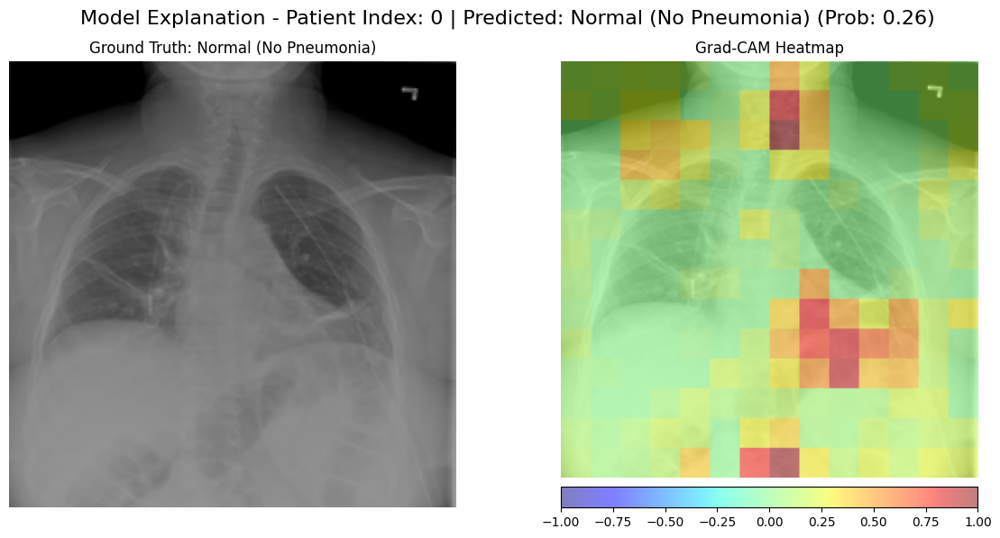

In [16]:
def visualize_explanation(dataset_idx, dataset, model, target_layer):
    """
    Visualizes the original image with its bounding box and the Grad-CAM heatmap side-by-side.
    """
    # Get the sample from the dataset (NOW GRABBING THE LABEL)
    img_tensor, lbl, bbox = dataset[dataset_idx]

    # Determine the diagnosis string based on the label
    diagnosis = "Pneumonia" if lbl == 1 else "Normal (No Pneumonia)"

    # Get model prediction
    model.eval()
    with torch.no_grad():
        output = model(img_tensor.unsqueeze(0).to(device))
        pred_prob = torch.sigmoid(output).item()
        pred_class = 1 if pred_prob > 0.5 else 0
        pred_diagnosis = "Pneumonia" if pred_class == 1 else "Normal (No Pneumonia)"

    # --- Denormalize and prepare image for display ---
    inv_normalize = transforms.Normalize(
        mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
        std=[1/0.229, 1/0.224, 1/0.225]
    )
    img_display = inv_normalize(img_tensor).permute(1, 2, 0).numpy()
    img_display = np.clip(img_display, 0, 1)

    # --- Generate Grad-CAM (Assuming you use the updated upsampled version!) ---
    heatmap = generate_grad_cam(model, img_tensor, target_layer)

    # --- Plotting Side-by-Side ---
    fig, axs = plt.subplots(1, 2, figsize=(12, 6))

    # Plot 1: Original Image with Ground Truth
    axs[0].imshow(img_display)
    axs[0].set_title(f"Ground Truth: {diagnosis}")
    axs[0].axis('off')

    orig_h, orig_w = 1024, 1024
    new_h, new_w = 224, 224
    x, y, w, h = bbox.numpy()
    x_scale, y_scale = new_w / orig_w, new_h / orig_h

    if w > 0 and h > 0:
        scaled_bbox = patches.Rectangle(
            (x * x_scale, y * y_scale), w * x_scale, h * y_scale,
            linewidth=2, edgecolor='g', facecolor='none'
        )
        axs[0].add_patch(scaled_bbox)

    # Plot 2: Grad-CAM Heatmap
    viz.visualize_image_attr(
        attr=heatmap,
        original_image=img_display,
        method='blended_heat_map',
        sign='all',
        cmap='jet',
        show_colorbar=True,
        plt_fig_axis=(fig, axs[1]),
        use_pyplot=False
    )

    # Update title to include what the model is predicting
    axs[1].set_title("Grad-CAM Heatmap")
    axs[1].axis('off')

    fig.suptitle(f"Model Explanation - Patient Index: {dataset_idx} | Predicted: {pred_diagnosis} (Prob: {pred_prob:.2f})", fontsize=16)
    plt.tight_layout()
    plt.show()

# --- Run Visualization ---
# Use the first image from our dummy dataset for this example
# visualize_explanation(dataset_idx=0, dataset=pneumonia_dataset, model=model, target_layer=model.layer4[-1])
visualize_explanation(dataset_idx=0, dataset=val_dataset, model=model, target_layer=target_layer)

In [17]:
def visualize_mrs_explanation(dataset_idx, dataset, model, target_layer, device):
    """
    Visualizes the original image with ALL its bounding boxes and the Grad-CAM heatmap side-by-side.
    Designed specifically for the MRSDataset.
    """
    # 1. Grab the image and label from the dataset
    img_tensor, lbl, mask = dataset[dataset_idx]

    # Grab the raw bounding boxes directly from the grouped dataframe
    bboxes = dataset.grouped_df.iloc[dataset_idx]['bboxes']

    diagnosis = "Pneumonia" if lbl == 1 else "Normal (No Pneumonia)"

    model.eval()
    with torch.no_grad():
        output = model(img_tensor.unsqueeze(0).to(device))
        pred_prob = torch.sigmoid(output).item()
        pred_class = 1 if pred_prob > 0.5 else 0
        pred_diagnosis = "Pneumonia" if pred_class == 1 else "Normal (No Pneumonia)"

    # Denormalize image for display
    inv_normalize = transforms.Normalize(
        mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
        std=[1/0.229, 1/0.224, 1/0.225]
    )
    img_display = inv_normalize(img_tensor).permute(1, 2, 0).numpy()
    img_display = np.clip(img_display, 0, 1)

    # Generate Grad-CAM heatmap
    heatmap = generate_grad_cam(model, img_tensor, target_layer)

    # Plotting
    fig, axs = plt.subplots(1, 2, figsize=(12, 6))

    # Plot 1: Original Image with ALL Ground Truth Bounding Boxes
    axs[0].imshow(img_display)
    axs[0].set_title(f"Ground Truth: {diagnosis}")
    axs[0].axis('off')

    orig_h, orig_w = 1024, 1024
    new_h, new_w = 224, 224
    x_scale, y_scale = new_w / orig_w, new_h / orig_h

    # Loop through and draw every bounding box for this patient
    for bbox in bboxes:
        x, y, w, h = bbox
        if w > 0 and h > 0:
            scaled_bbox = patches.Rectangle(
                (x * x_scale, y * y_scale), w * x_scale, h * y_scale,
                linewidth=2, edgecolor='g', facecolor='none'
            )
            axs[0].add_patch(scaled_bbox)

    # Plot 2: Grad-CAM Heatmap Overlay
    viz.visualize_image_attr(
        attr=heatmap,
        original_image=img_display,
        method='blended_heat_map',
        sign='all',
        cmap='jet',
        show_colorbar=True,
        plt_fig_axis=(fig, axs[1]),
        use_pyplot=False
    )

    axs[1].set_title("Grad-CAM Heatmap")
    axs[1].axis('off')

    fig.suptitle(f"Model Explanation - Patient Index: {dataset_idx} | Predicted: {pred_diagnosis} (Prob: {pred_prob:.2f})", fontsize=16)
    plt.tight_layout()
    plt.show()

# Example usage:
# visualize_mrs_explanation(dataset_idx=0, dataset=mrs_dataset, model=model, target_layer=target_layer, device=device)

### Visualize more results

Visualizing Sample #89


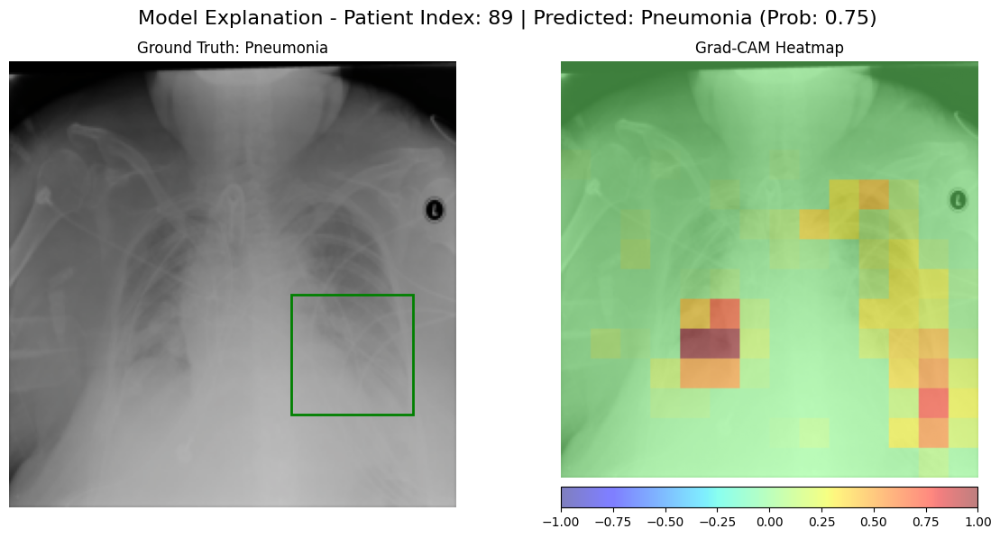

Visualizing Sample #3162


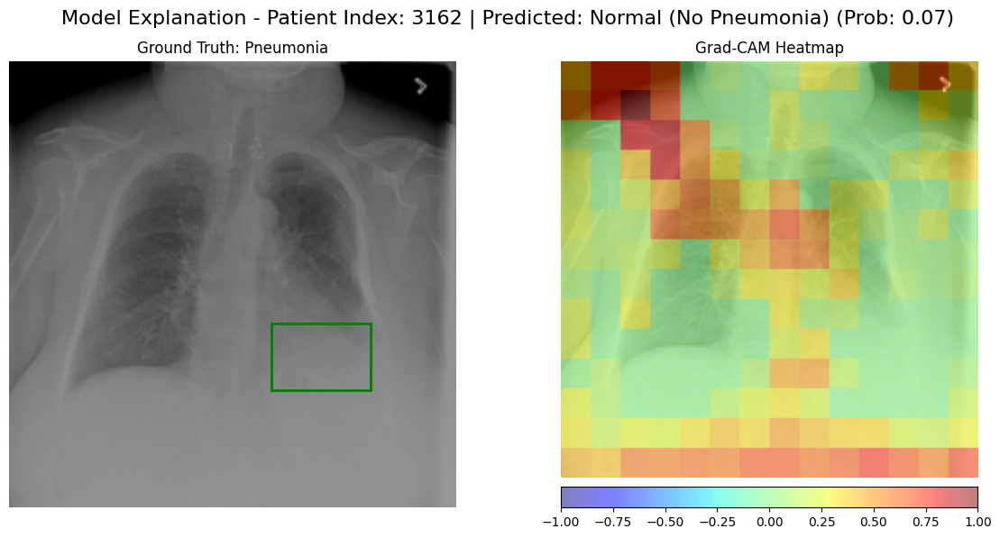

Visualizing Sample #133


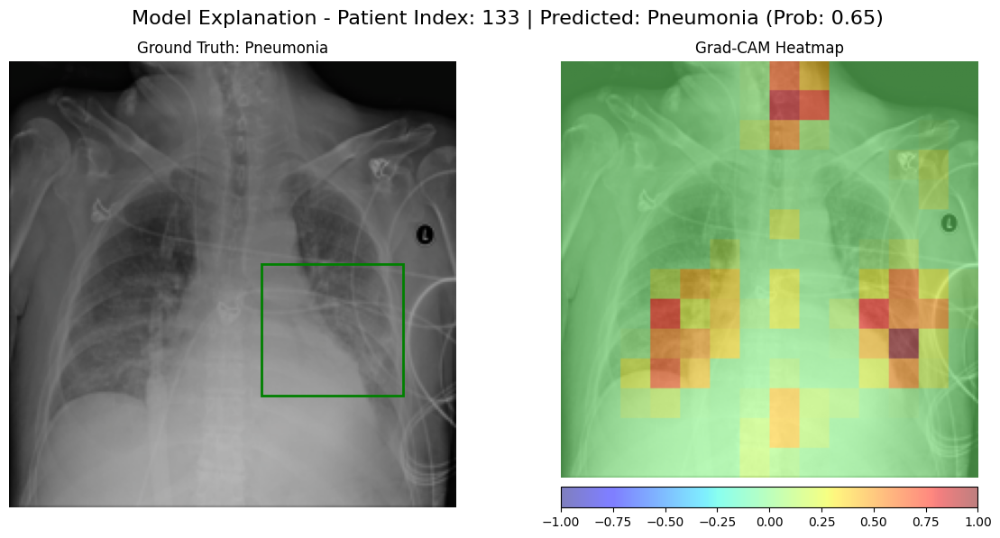

Visualizing Sample #3616


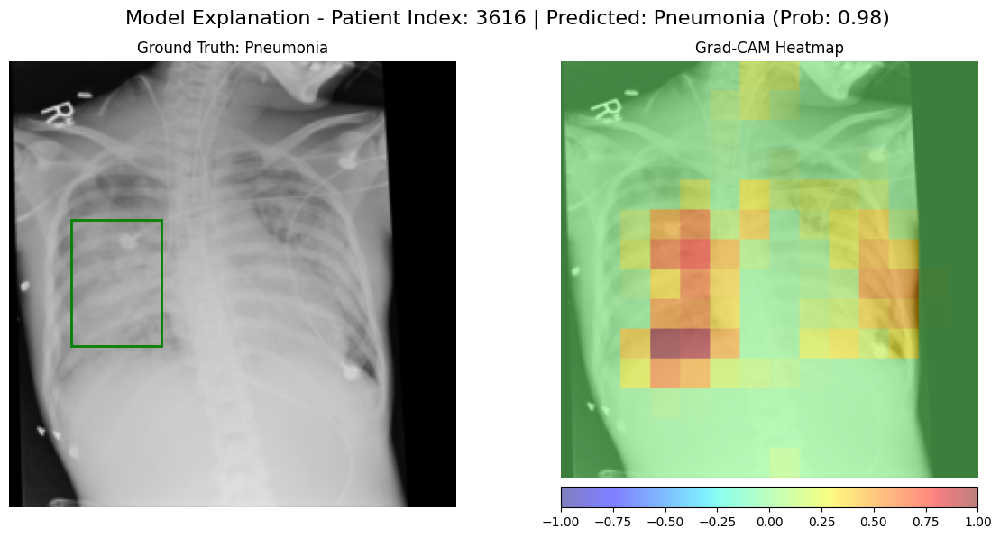

Visualizing Sample #2732


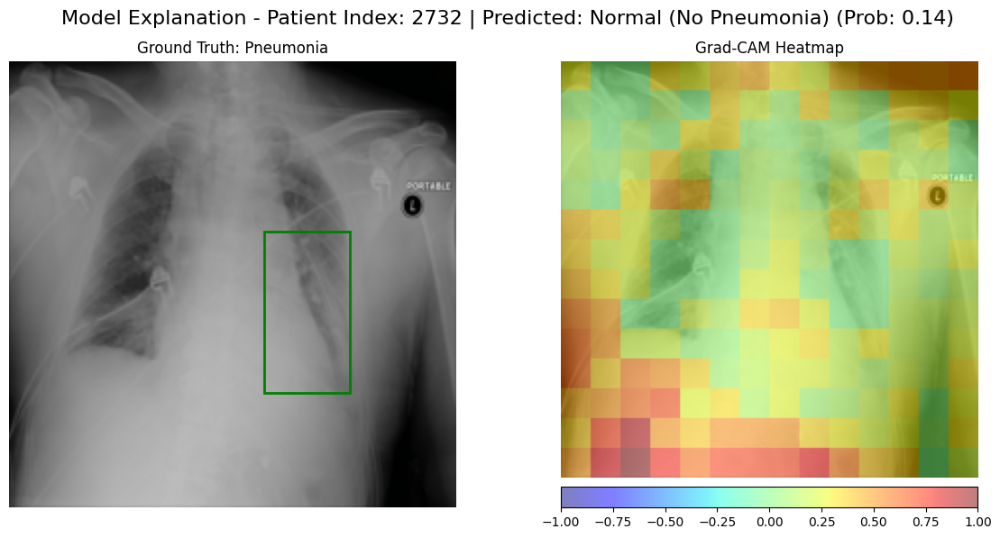

Visualizing Sample #2618


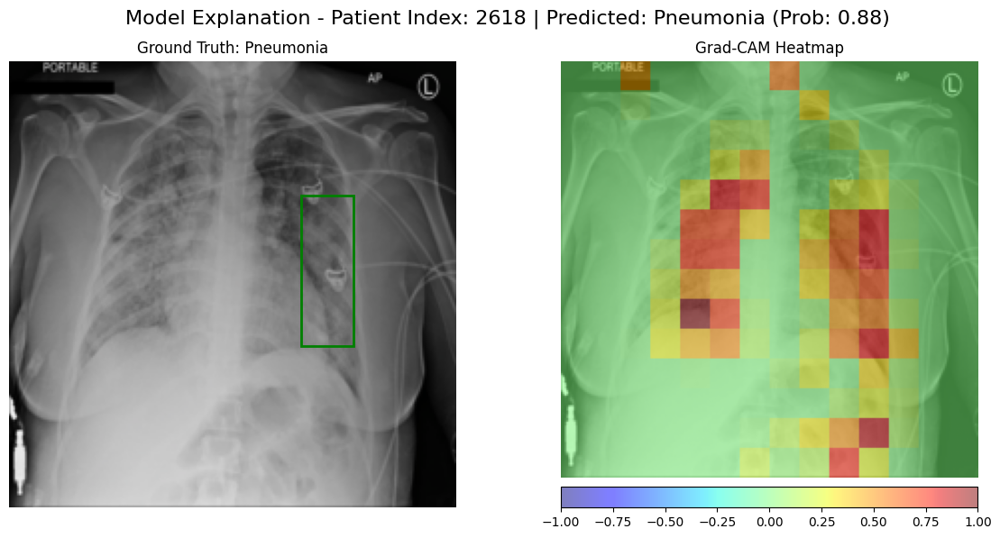

Visualizing Sample #381


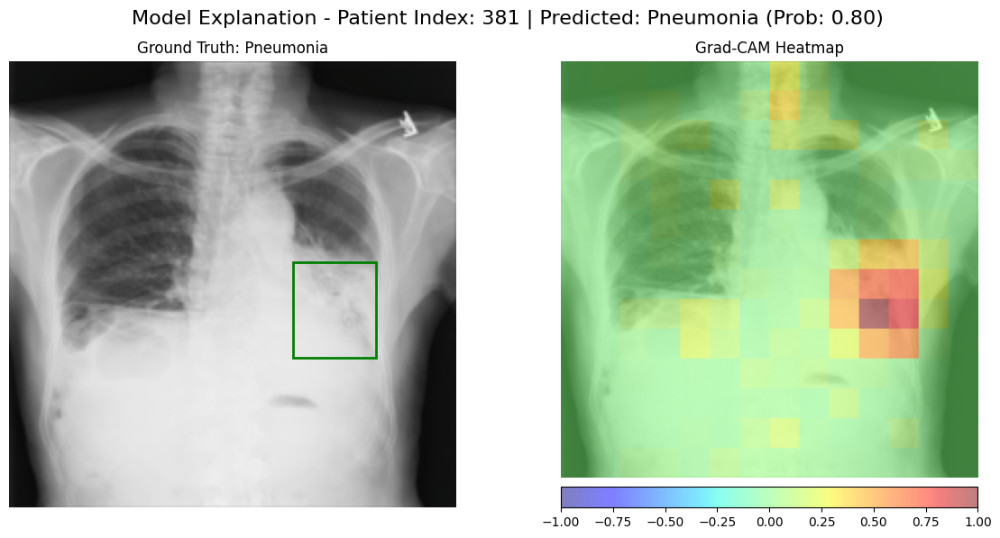

Visualizing Sample #4053


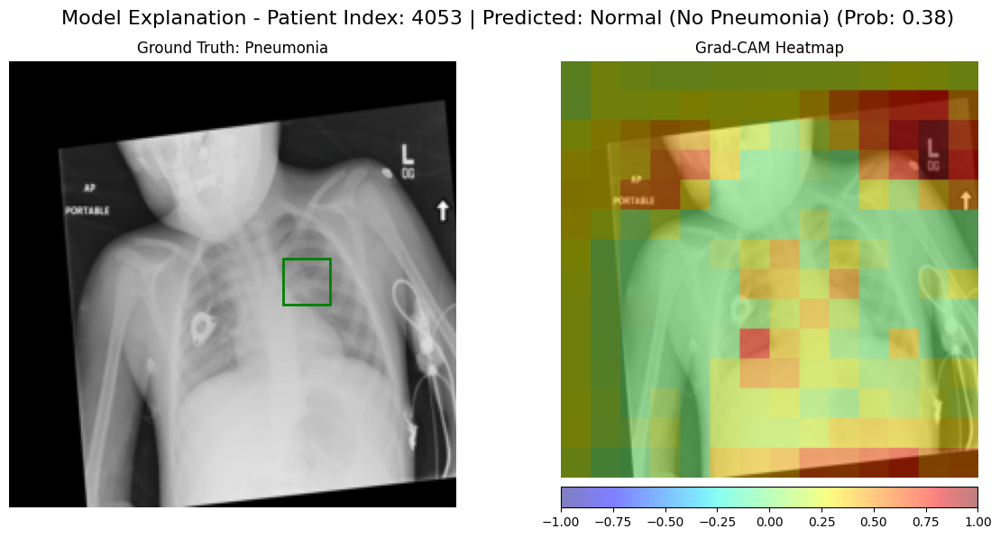

Visualizing Sample #2430


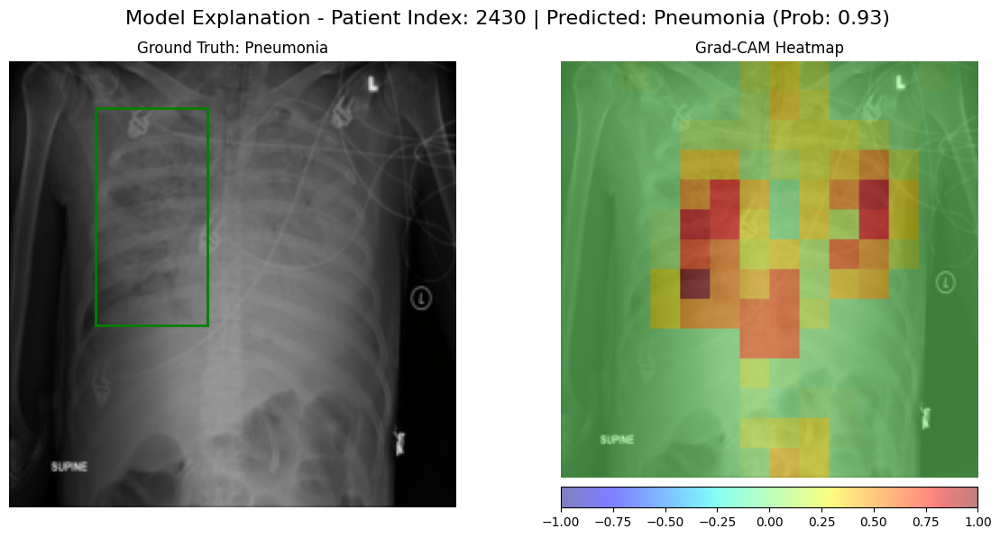

Visualizing Sample #600


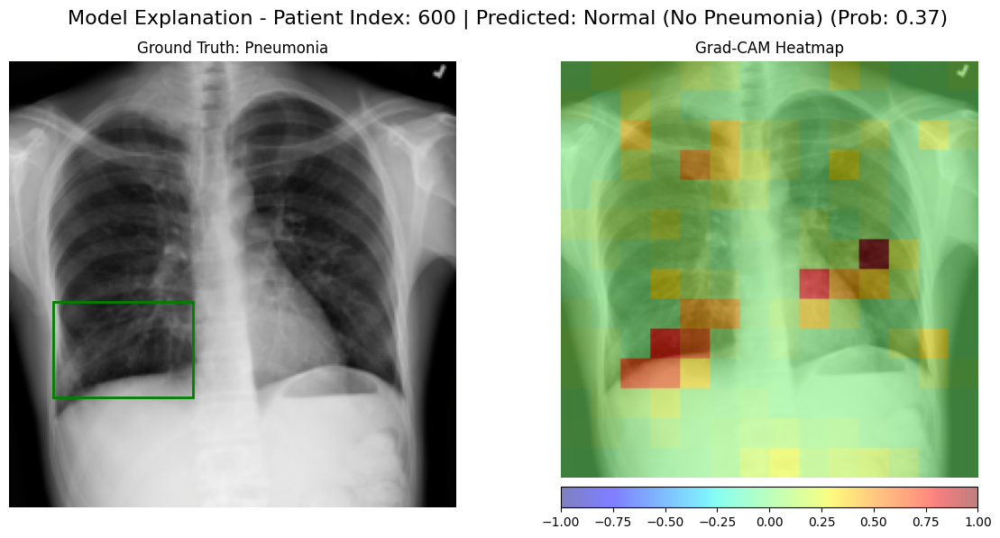

In [18]:
# Filter for pneumonia-positive cases in the validation dataset
pneumonia_positive_indices = [i for i, (img, label, bbox) in enumerate(val_dataset) if label == 1]

# Choose a subset of these indices for visualization (e.g., 10 random positive cases)
if len(pneumonia_positive_indices) > 0:
    num_samples_to_visualize = min(10, len(pneumonia_positive_indices)) # Don't request more than available
    idxs = np.random.choice(pneumonia_positive_indices, size=num_samples_to_visualize, replace=False)
else:
    print("No pneumonia-positive cases found in the validation dataset to visualize.")
    idxs = []

for i in idxs:
    print(f"Visualizing Sample #{i}")
    visualize_explanation(
        dataset_idx=i,
        dataset=val_dataset,
        model=model,
        target_layer=target_layer
    )

Visualizing Sample #878


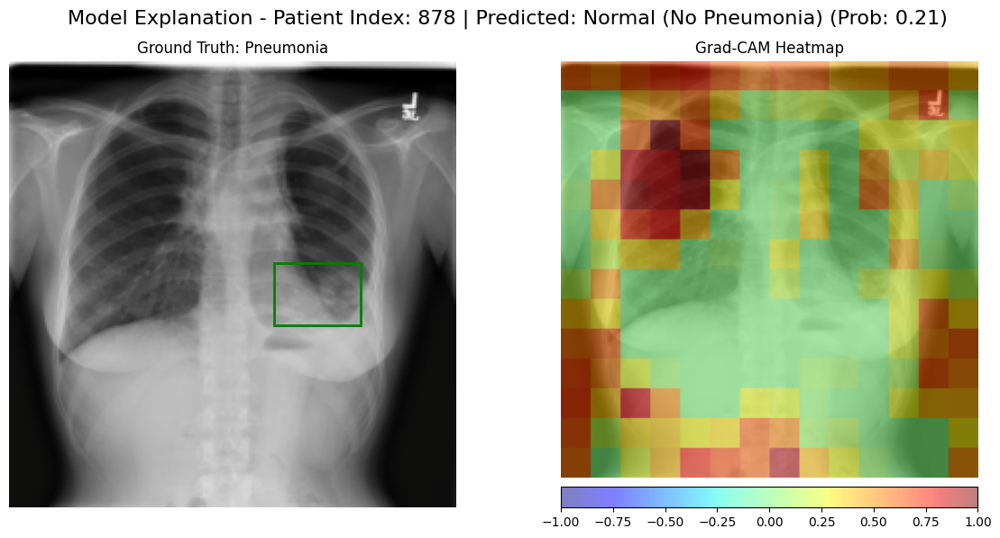

Visualizing Sample #3340


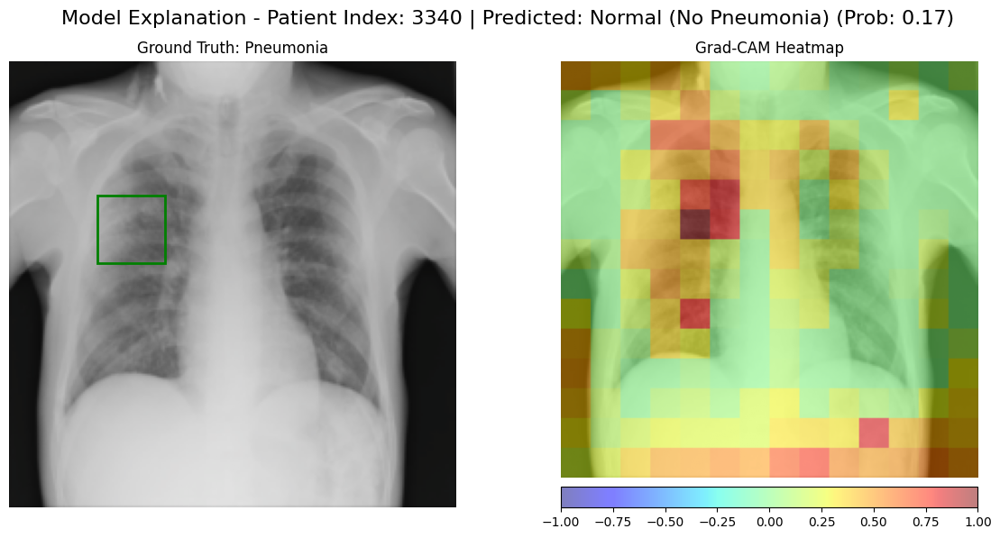

Visualizing Sample #3331


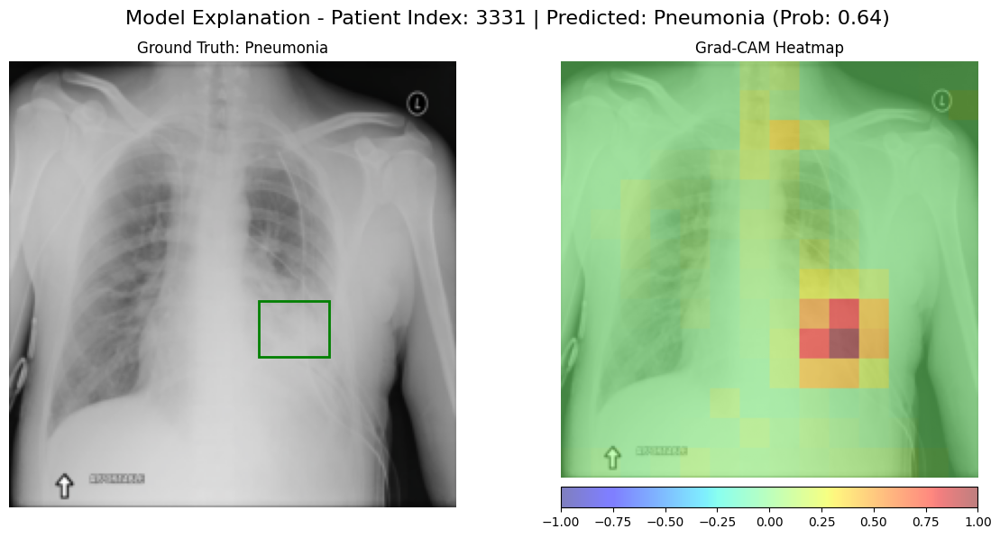

Visualizing Sample #2605


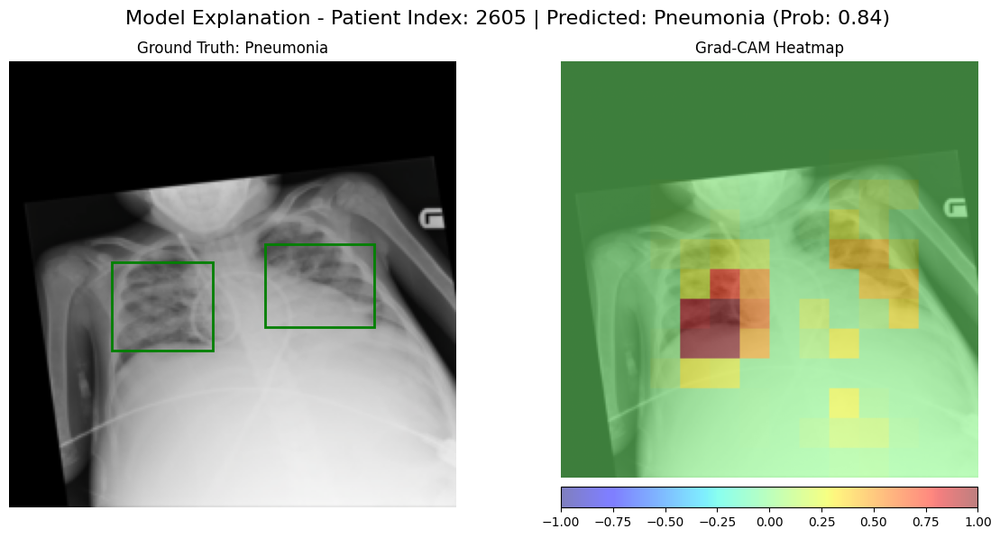

Visualizing Sample #528


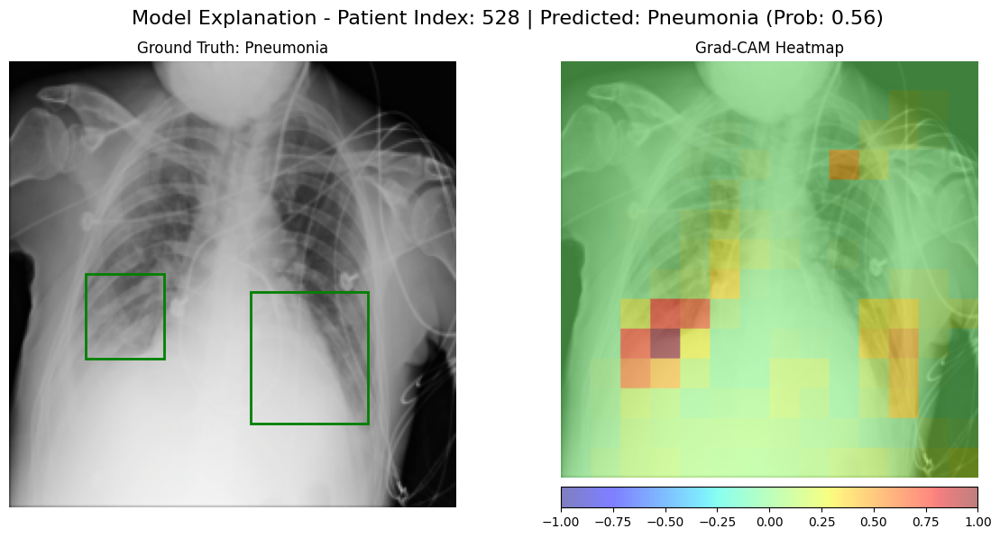

Visualizing Sample #572


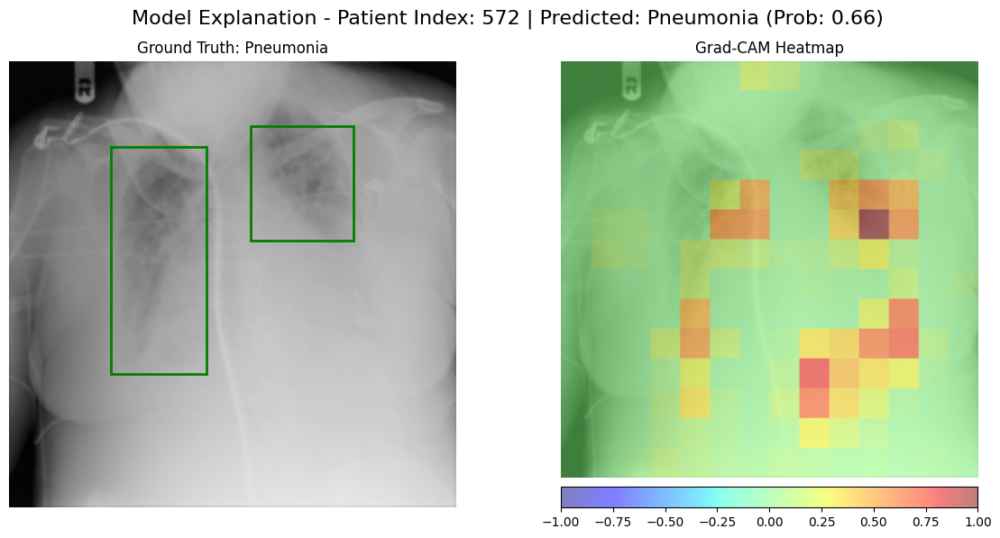

Visualizing Sample #2974


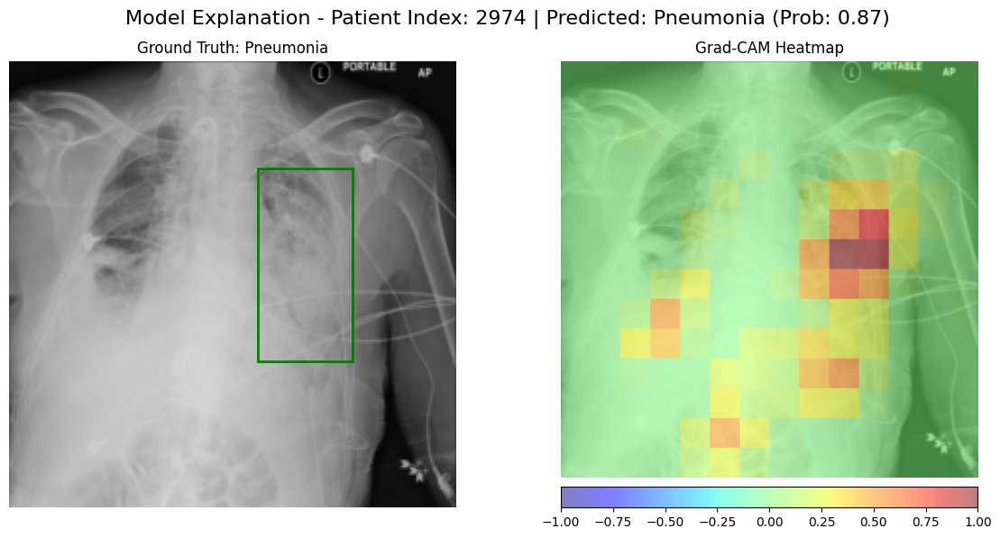

Visualizing Sample #1721


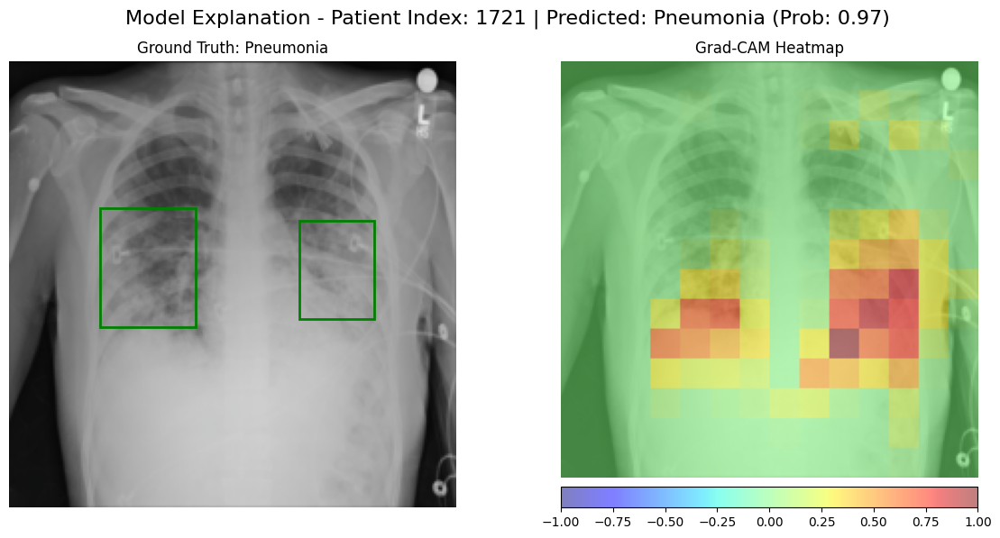

Visualizing Sample #828


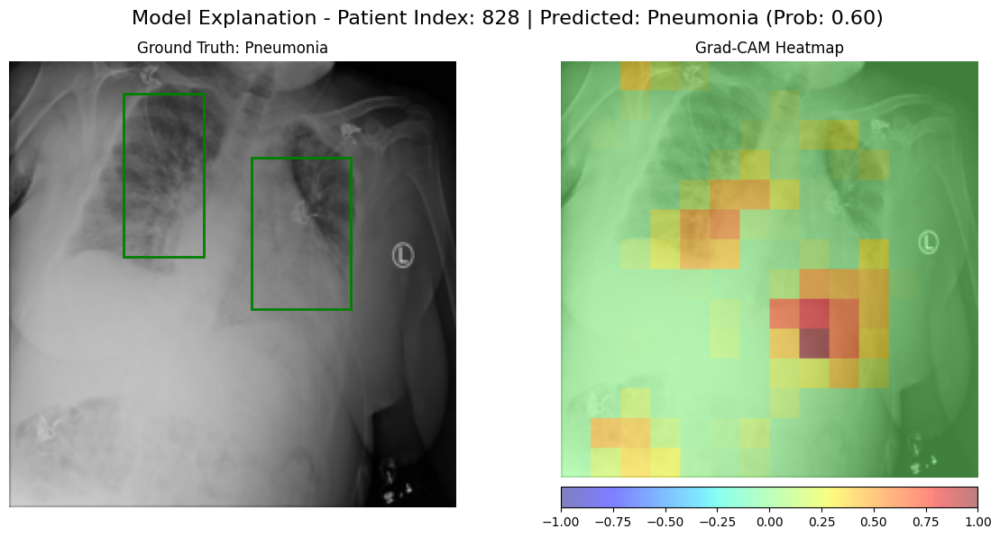

Visualizing Sample #2970


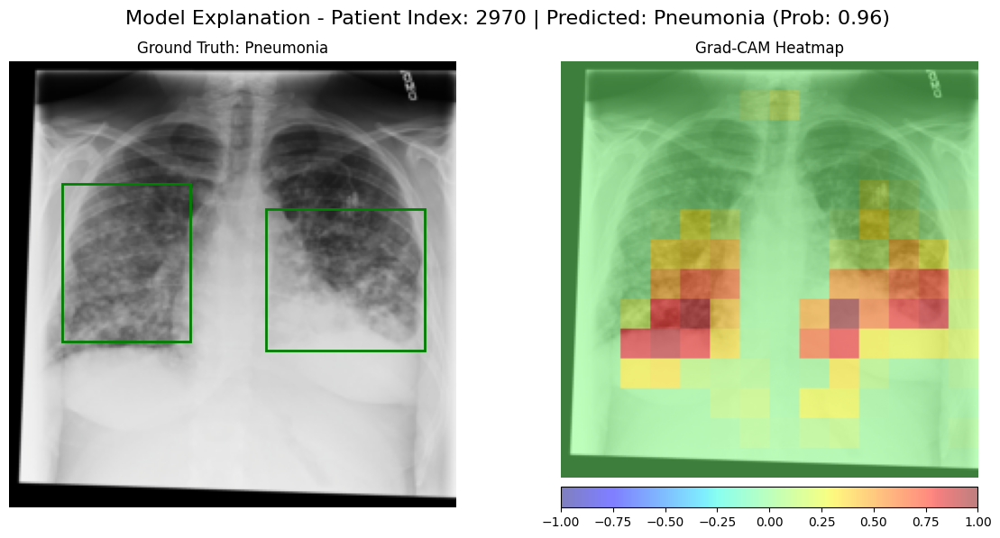

In [19]:
# New complete visualization, now with all the bounding boxes per patient.

# 1. Instantiate the MRSDataset for the validation dataframe
mrs_val_dataset = MRSDataset(val_df, img_folder, transform=val_test_transform)

# 2. Filter for pneumonia-positive cases in the new grouped dataset
# Note the unpacking is now (img, label, mask) to match MRSDataset
pneumonia_positive_indices = [i for i, (img, label, mask) in enumerate(mrs_val_dataset) if label == 1]

# Choose a subset of these indices for visualization (e.g., 10 random positive cases)
if len(pneumonia_positive_indices) > 0:
    num_samples_to_visualize = min(10, len(pneumonia_positive_indices)) # Don't request more than available
    idxs = np.random.choice(pneumonia_positive_indices, size=num_samples_to_visualize, replace=False)
else:
    print("No pneumonia-positive cases found in the validation dataset to visualize.")
    idxs = []

for i in idxs:
    print(f"Visualizing Sample #{i}")
    visualize_mrs_explanation(
        dataset_idx=i,
        dataset=mrs_val_dataset,  # MUST use the grouped MRS dataset here
        model=model,
        target_layer=target_layer,
        device=device             # MUST pass the device argument
    )

Visualizing Layer 3 heatmaps
Visualizing Sample #878


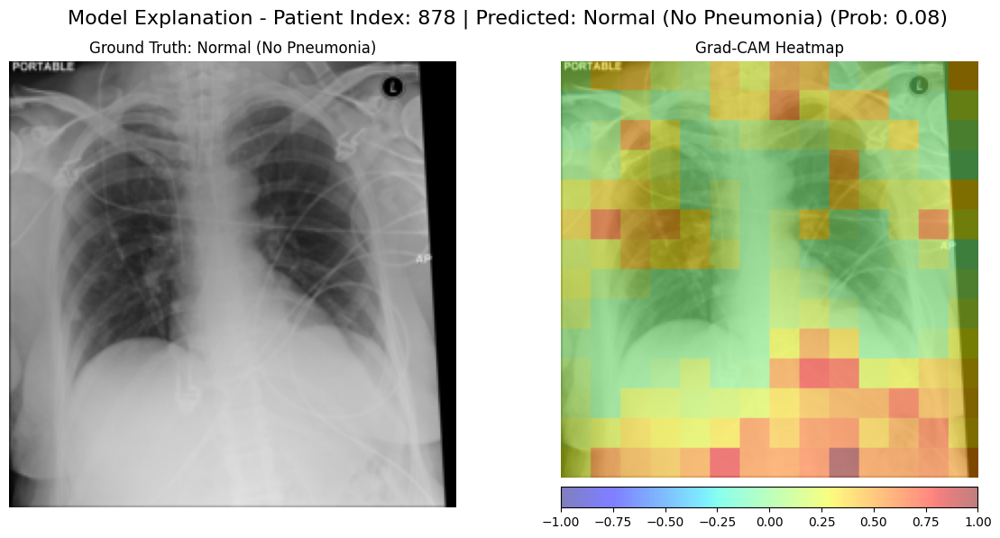

Visualizing Sample #3340


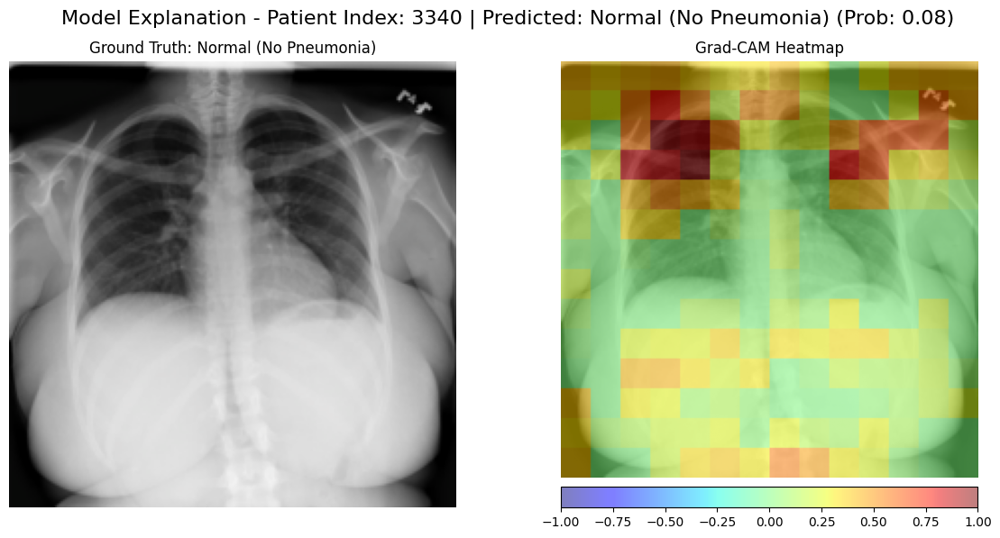

Visualizing Sample #3331


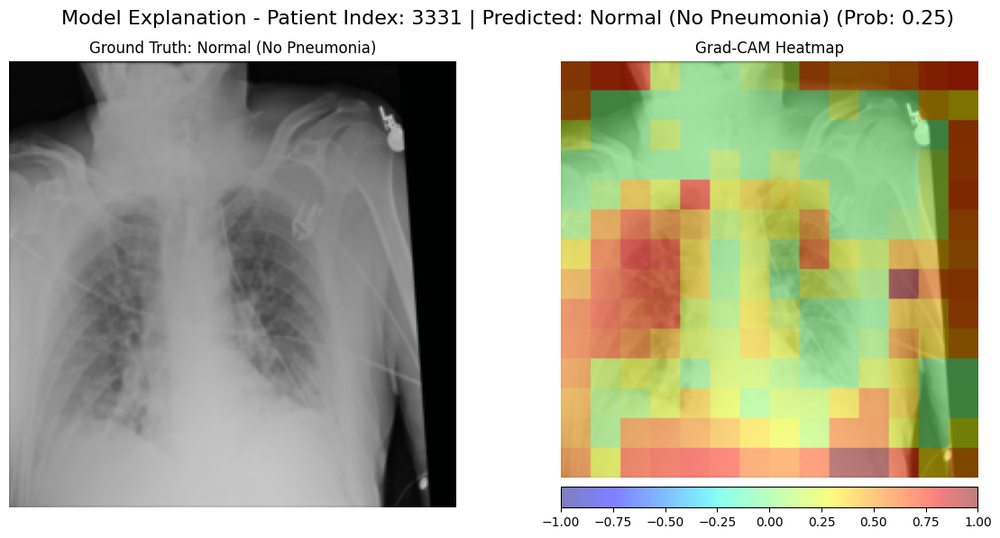

Visualizing Sample #2605


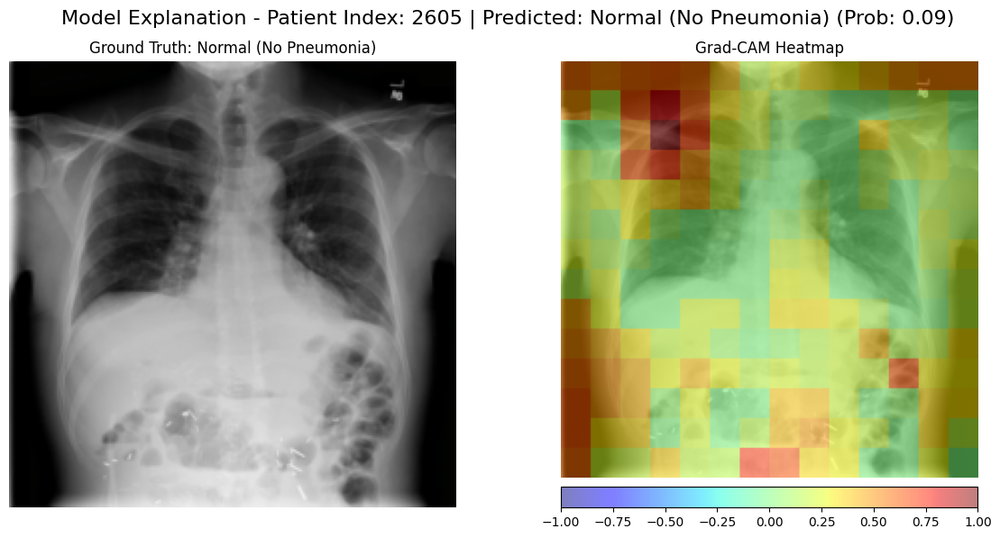

Visualizing Sample #528


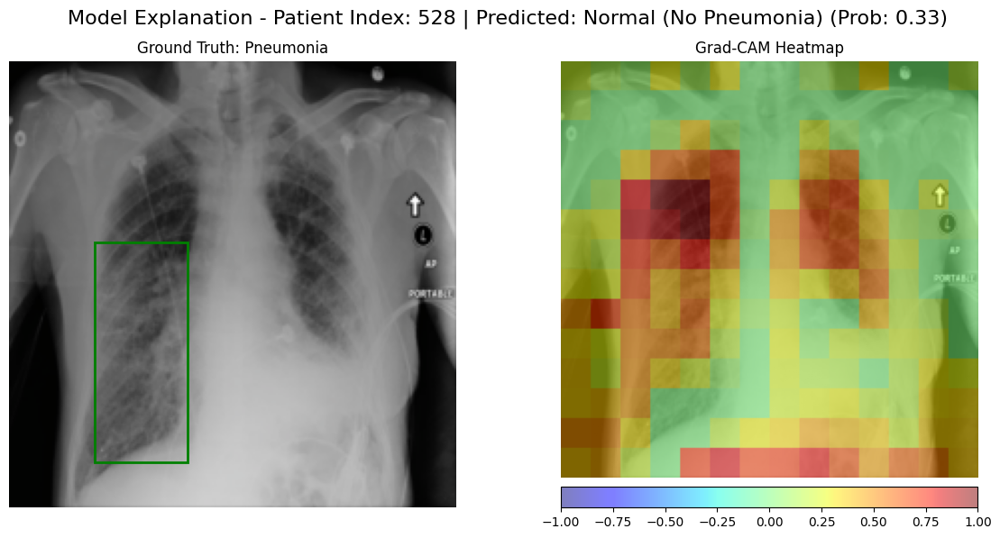

Visualizing Sample #572


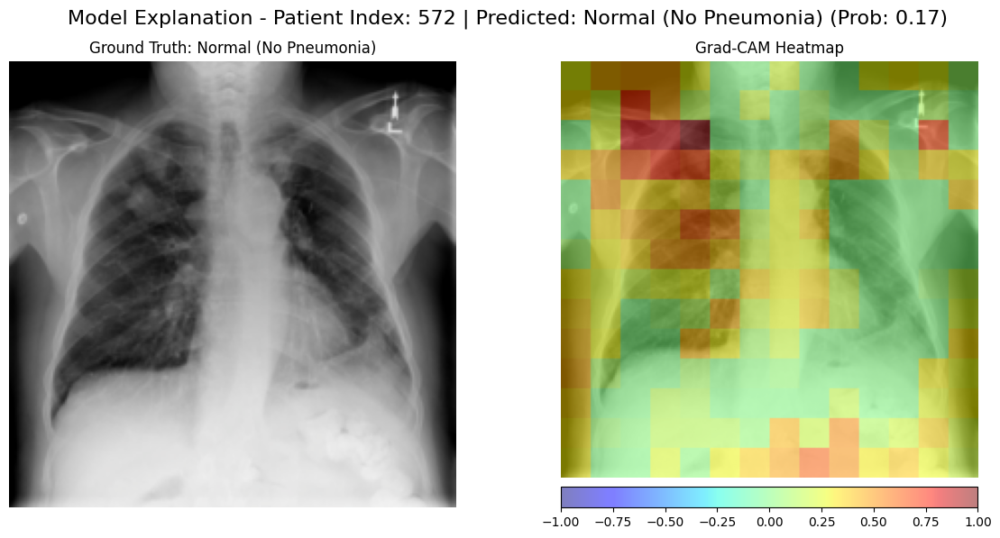

Visualizing Sample #2974


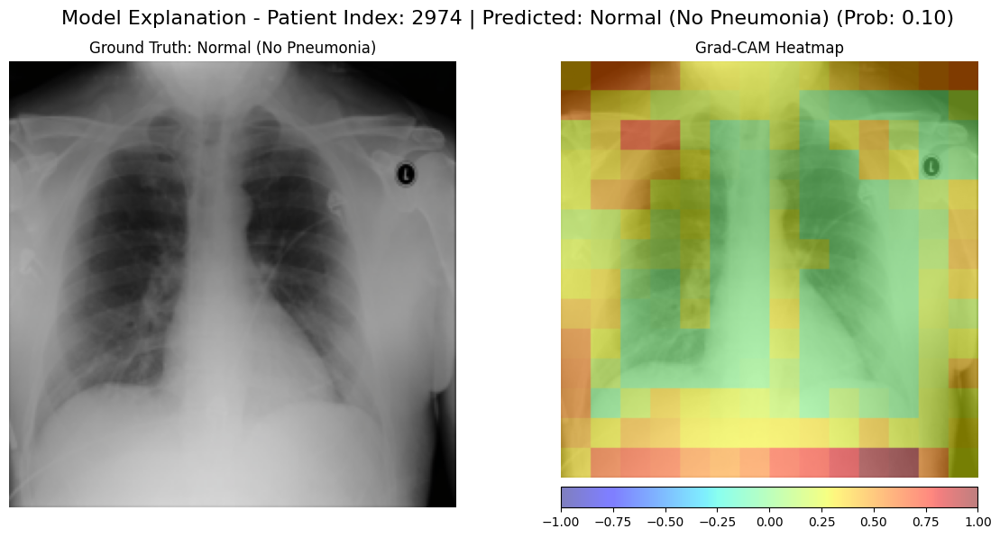

Visualizing Sample #1721


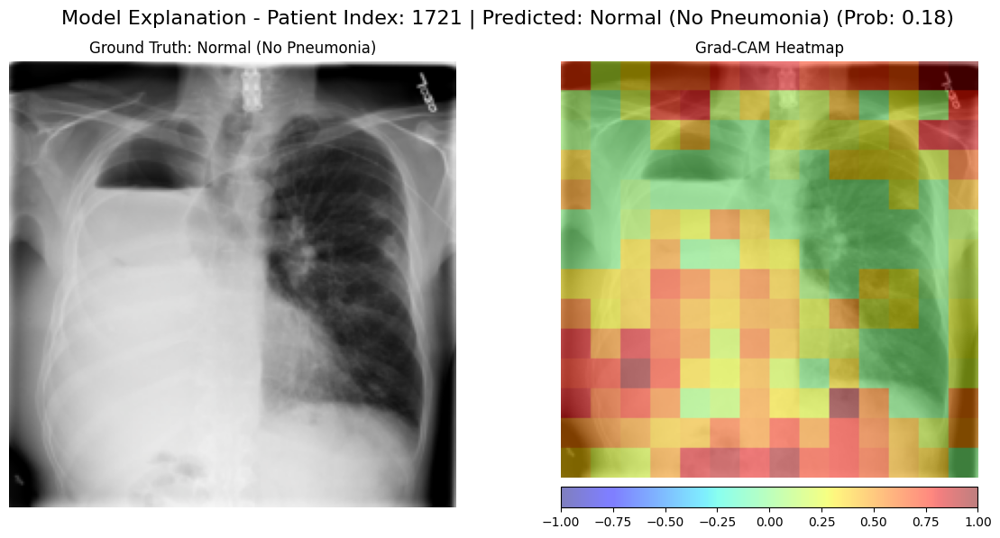

Visualizing Sample #828


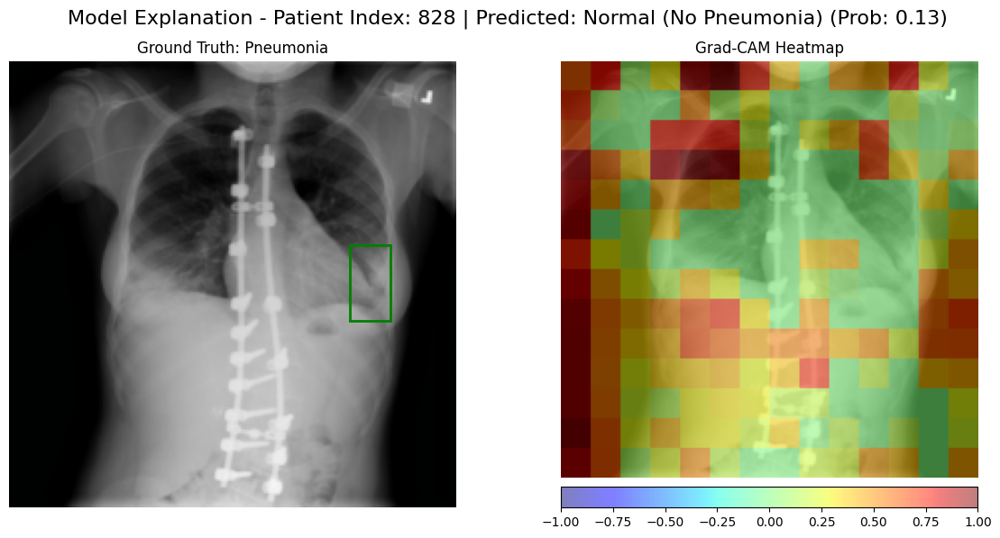

Visualizing Sample #2970


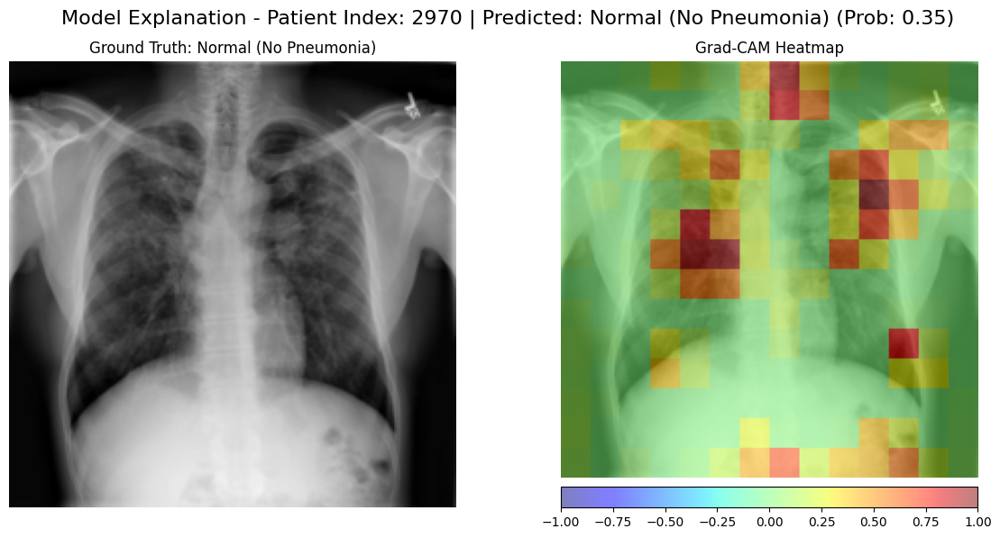

In [20]:
# Visualization for layer3
print("Visualizing Layer 3 heatmaps")

# Reuse the idxs from the previous cell, which now prioritize pneumonia-positive cases
if 'idxs' in locals() and len(idxs) > 0:
    for i in idxs:
        print(f"Visualizing Sample #{i}")
        visualize_explanation(
            dataset_idx=i,
            dataset=val_dataset,
            model=model,
            target_layer=model.layer3[-1] # Layer3 here !!!
        )
else:
    print("No indices available for Layer 3 visualization. Run the previous cell to select indices.")

---

# Evaluating the technique - MRS

In [21]:
import torch
import numpy as np

def calculate_mrs_for_dataset(model, test_dataloader, target_layer, device):
    """
    Computes the Mean Relevance Score (MRS) over the test dataset.
    We evaluate this specifically on positive pneumonia cases (where bounding boxes exist).
    """
    model.eval()
    relevance_scores = []

    # Original image dimensions from the RSNA dataset
    orig_h, orig_w = 1024, 1024
    new_h, new_w = 224, 224
    x_scale, y_scale = new_w / orig_w, new_h / orig_h

    print("Calculating MRS over the test set...")

    for images, labels, bboxes in test_dataloader:
        images = images.to(device)
        labels = labels.to(device)

        for i in range(images.size(0)):
            # Only calculate alignment for actual Pneumonia cases (label == 1)
            if labels[i].item() == 1:
                img_tensor = images[i]
                bbox = bboxes[i].numpy()
                x, y, w, h = bbox

                # Check if a valid bounding box exists
                if w > 0 and h > 0:
                    # 1. Generate the heatmap using your existing Captum Grad-CAM function
                    heatmap = generate_grad_cam(model, img_tensor, target_layer)

                    # Ensure heatmap is strictly positive (ReLU-like) for proper fractional scoring
                    heatmap = np.maximum(heatmap, 0)

                    # 2. Scale the bounding box to match the 224x224 heatmap
                    x_scaled = int(x * x_scale)
                    y_scaled = int(y * y_scale)
                    w_scaled = int(w * x_scale)
                    h_scaled = int(h * y_scale)

                    # 3. Create a binary mask for the bounding box
                    mask = np.zeros((new_h, new_w))
                    # Prevent out-of-bounds indexing
                    y_end = min(y_scaled + h_scaled, new_h)
                    x_end = min(x_scaled + w_scaled, new_w)
                    mask[y_scaled:y_end, x_scaled:x_end] = 1.0

                    # 4. Calculate R_i: Sum of relevance inside the bbox / Total relevance in the image
                    total_relevance = np.sum(heatmap)

                    if total_relevance > 0:
                        relevance_inside_bbox = np.sum(heatmap * mask)
                        r_i = relevance_inside_bbox / total_relevance
                        relevance_scores.append(r_i)

    # Calculate the Mean Relevance Score (MRS)
    if len(relevance_scores) > 0:
        mrs = np.mean(relevance_scores)
        print(f"Evaluated MRS on {len(relevance_scores)} positive test images.")
        print(f"Mean Relevance Score (MRS): {mrs:.4f}")
        return mrs
    else:
        print("No positive cases with bounding boxes found in the provided dataloader.")
        return 0.0

In [22]:
def calculate_mrs_for_dataset(model, mrs_dataloader, target_layer, device):
    """
    Computes the Mean Relevance Score (MRS) over the unified region of interest.
    """
    model.eval()
    relevance_scores = []

    print("Calculating MRS over the grouped test set...")

    for images, labels, masks in mrs_dataloader:
        images = images.to(device)
        labels = labels.to(device)
        masks = masks.numpy()

        for i in range(images.size(0)):
            # Only evaluate actual Pneumonia cases
            if labels[i].item() == 1:
                img_tensor = images[i]
                mask = masks[i]

                # Proceed only if the aggregated mask has an area > 0
                if np.sum(mask) > 0:
                    # 1. Generate the heatmap using your existing Captum function
                    heatmap = generate_grad_cam(model, img_tensor, target_layer)

                    # Squeeze potential channel dimensions (224, 224, 1) -> (224, 224)
                    # to strictly match the mask shape and prevent NumPy broadcast errors
                    heatmap = np.squeeze(heatmap)
                    heatmap = np.maximum(heatmap, 0)

                    # 2. Calculate R_i: Sum of relevance inside all bboxes / Total relevance
                    total_relevance = np.sum(heatmap)

                    if total_relevance > 0:
                        relevance_inside_bbox = np.sum(heatmap * mask)
                        r_i = relevance_inside_bbox / total_relevance
                        relevance_scores.append(r_i)

    # Calculate the Mean Relevance Score (MRS)
    if len(relevance_scores) > 0:
        mrs = np.mean(relevance_scores)
        print(f"Evaluated MRS on {len(relevance_scores)} unique positive test images.")
        print(f"Mean Relevance Score (MRS): {mrs:.4f}")
        return mrs
    else:
        print("No positive cases with bounding boxes found in the provided dataloader.")
        return 0.0

In [23]:
# --- to run it ---
# test_mrs = calculate_mrs_for_dataset(model, test_dataloader, target_layer, device)

In [24]:
# --- to run it ---
# test_mrs = calculate_mrs_for_dataset(model, test_dataloader, target_layer, device)

# Optionally, you can also calculate MRS on the validation set for comparison
# val_mrs = calculate_mrs_for_dataset(model, val_dataloader, target_layer, device)
# print(f"Validation MRS: {val_mrs:.4f}")

In [25]:
# val_mrs = calculate_mrs_for_dataset(model, val_dataloader, target_layer, device)
# print(f"Validation MRS: {val_mrs:.4f}")

In [26]:
mrs_dataset = MRSDataset(test_df, img_folder, transform=val_test_transform)
mrs_dataloader = DataLoader(mrs_dataset, batch_size=32, shuffle=False, num_workers=2)

final_mrs = calculate_mrs_for_dataset(model, mrs_dataloader, target_layer, device)

Calculating MRS over the grouped test set...
Evaluated MRS on 894 unique positive test images.
Mean Relevance Score (MRS): 0.3013


---

## Metrics and results

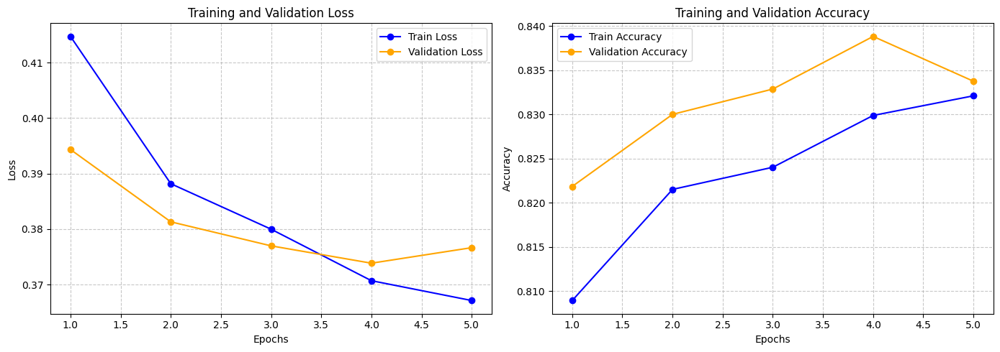

In [29]:
# Check if the training variables exist in the environment
if 'global_train_losses' in globals():
    epochs = range(1, len(global_train_losses) + 1)

    fig, axs = plt.subplots(1, 2, figsize=(14, 5))

    # Plot Training & Validation Accuracy
    axs[1].plot(epochs, global_train_accuracies, label='Train Accuracy', marker='o', color='blue')
    axs[1].plot(epochs, global_val_accuracies, label='Validation Accuracy', marker='o', color='orange')
    axs[1].set_title('Training and Validation Accuracy')
    axs[1].set_xlabel('Epochs')
    axs[1].set_ylabel('Accuracy')
    axs[1].legend()
    axs[1].grid(True, linestyle='--', alpha=0.7)

    # Plot Training & Validation Loss
    axs[0].plot(epochs, global_train_losses, label='Train Loss', marker='o', color='blue')
    axs[0].plot(epochs, global_val_losses, label='Validation Loss', marker='o', color='orange')
    axs[0].set_title('Training and Validation Loss')
    axs[0].set_xlabel('Epochs')
    axs[0].set_ylabel('Loss')
    axs[0].legend()
    axs[0].grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()
else:
    print("Training metrics not found. Ensure the training cell has been run.")

--- Starting Final Evaluation on Test Set ---
✅ Final Test Loss: 0.3720
✅ Final Test Accuracy: 0.8319

--- Clinical Evaluation Metrics ---
              precision    recall  f1-score   support

      Normal       0.88      0.88      0.88      3109
   Pneumonia       0.73      0.74      0.73      1435

    accuracy                           0.83      4544
   macro avg       0.81      0.81      0.81      4544
weighted avg       0.83      0.83      0.83      4544



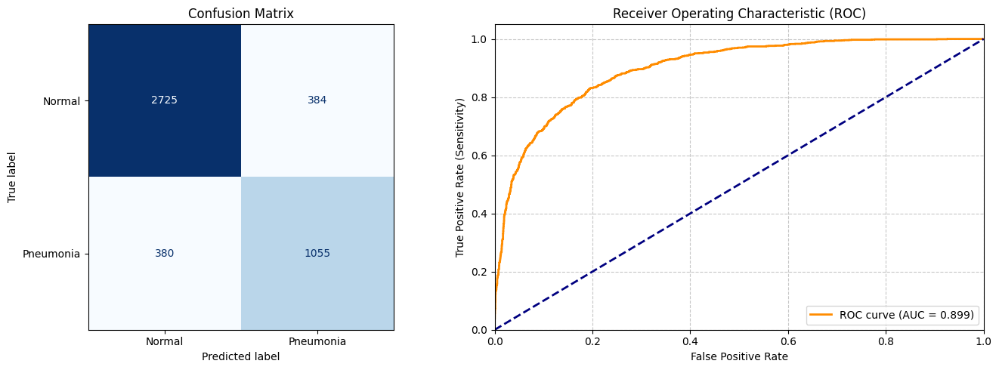

In [28]:
from sklearn.metrics import roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay, classification_report

# 1. Run the evaluation to get ground truth labels and model probabilities
# (This calls your existing evaluate_test_set function)
test_loss, test_acc, true_labels, model_probs = evaluate_test_set(model, test_dataloader, criterion, device)

# 2. Convert probabilities to binary predictions using a 0.5 threshold
binary_preds = (np.array(model_probs) > 0.5).astype(int)

# 3. Print the comprehensive classification report
print("\n--- Clinical Evaluation Metrics ---")
print(classification_report(true_labels, binary_preds, target_names=["Normal", "Pneumonia"]))

# 4. Compute ROC curve and AUC (Area Under Curve)
fpr, tpr, thresholds = roc_curve(true_labels, model_probs)
roc_auc = auc(fpr, tpr)

# 5. Plot Confusion Matrix and ROC Curve side-by-side
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Plot Confusion Matrix
cm = confusion_matrix(true_labels, binary_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Pneumonia"])
disp.plot(ax=axs[0], cmap='Blues', colorbar=False)
axs[0].set_title('Confusion Matrix')

# Plot ROC Curve
axs[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
axs[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--') # Diagonal representing random guessing
axs[1].set_xlim([0.0, 1.0])
axs[1].set_ylim([0.0, 1.05])
axs[1].set_xlabel('False Positive Rate')
axs[1].set_ylabel('True Positive Rate (Sensitivity)')
axs[1].set_title('Receiver Operating Characteristic (ROC)')
axs[1].legend(loc="lower right")
axs[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()